In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

In [6]:
import kagglehub
import os

In [7]:
# Download latest version
path = kagglehub.dataset_download("willianoliveiragibin/olympics-2024")

print("Path to dataset files:", path)

df = pd.read_csv(os.path.join(path, 'athletes new.csv'))

Path to dataset files: C:\Users\Samsung\.cache\kagglehub\datasets\willianoliveiragibin\olympics-2024\versions\1


In [45]:
display(df.head())

,code,name,name_short,name_tv,gender,function,country_code,country,country_full,nationality,nationality_full,nationality_code,height,weight,disciplines,events,birth_date,age,faixa_etaria
0,1535420,VALENCIA Alejandra,VALENCIA A,Alejandra VALENCIA,Female,Athlete,MEX,Mexico,Mexico,Mexico,Mexico,MEX,171.0,67.0,['Archery'],"[""Women's Individual"", ""Women's Team"", 'Mixed ...",1994-10-17,30,20-29
1,1535429,RUIZ Angela,RUIZ A,Angela RUIZ,Female,Athlete,MEX,Mexico,Mexico,Mexico,Mexico,MEX,171.0,67.0,['Archery'],"[""Women's Individual"", ""Women's Team""]",2006-07-28,18,<20
2,1535430,GRANDE Matias,GRANDE M,Matias GRANDE,Male,Athlete,MEX,Mexico,Mexico,Mexico,Mexico,MEX,185.0,88.0,['Archery'],"[""Men's Individual"", ""Men's Team"", 'Mixed Team']",2004-04-26,20,<20
3,1536460,ROJAS Carlos,ROJAS C,Carlos ROJAS,Male,Athlete,MEX,Mexico,Mexico,Mexico,Mexico,MEX,185.0,88.0,['Archery'],"[""Men's Individual"", ""Men's Team""]",2000-01-14,24,20-29
4,1536467,MARTINEZ WING Bruno,MARTINEZ WING B,Bruno MARTINEZ WING,Male,Athlete,MEX,Mexico,Mexico,Mexico,Mexico,MEX,185.0,88.0,['Archery'],"[""Men's Individual"", ""Men's Team""]",1998-03-08,26,20-29


In [46]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11115 entries, 0 to 11114
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   code              11115 non-null  int64         
 1   name              11115 non-null  object        
 2   name_short        11115 non-null  object        
 3   name_tv           11115 non-null  object        
 4   gender            11115 non-null  object        
 5   function          11115 non-null  object        
 6   country_code      11115 non-null  object        
 7   country           11115 non-null  object        
 8   country_full      11115 non-null  object        
 9   nationality       11115 non-null  object        
 10  nationality_full  11115 non-null  object        
 11  nationality_code  11115 non-null  object        
 12  height            11115 non-null  float64       
 13  weight            11115 non-null  float64       
 14  disciplines       1111

In [47]:
df.describe()

,code,height,weight,birth_date,age
count,1.111500e+04,11115.000000,11115.000000,11115,11115.000000
mean,1.887426e+06,178.476833,77.689519,1997-07-07 15:02:59.757085184,26.970130
min,1.532872e+06,140.000000,51.000000,1954-12-01 00:00:00,12.000000
25%,1.888186e+06,171.000000,67.000000,1994-07-20 00:00:00,23.000000
50%,1.918842e+06,178.000000,88.000000,1998-02-01 00:00:00,26.000000
75%,1.948950e+06,185.000000,88.000000,2001-03-22 00:00:00,30.000000
max,9.460001e+06,222.000000,113.000000,2012-08-11 00:00:00,70.000000
std,3.587687e+05,9.477670,10.575621,NaN,5.408739


In [48]:
df.duplicated().sum()


np.int64(0)

In [49]:
df.isna().sum()

code                0
name                0
name_short          0
name_tv             0
gender              0
function            0
country_code        0
country             0
country_full        0
nationality         0
nationality_full    0
nationality_code    0
height              0
weight              0
disciplines         0
events              0
birth_date          0
age                 0
faixa_etaria        0
dtype: int64

Discussao: Alguma feature tem dados ausentes nos seus dados?

resposta: sim em peso existem 16 atletas sem peso oque pode atraplhar a filtragem alguns dados como a media.


## Conhecimento de Domínio

No dataset atual, temos a feature 'weight' com dados ausentes (16 valores `NaN`) e uma grande quantidade de valores `0.0`, que também são efetivamente dados ausentes ou inválidos. A análise do `df.describe()` mostrou que até 75% dos atletas têm um peso registrado como `0.0`.

**Observações sobre a variável 'weight':**

*   **Implausibilidade:** Não faz sentido que atletas olímpicos tenham um peso de `0.0` ou que essa informação esteja faltando. O peso é um dado fundamental para a maioria das modalidades esportivas e para a caracterização física de um atleta.
*   **Origem dos Dados:** Considerando que o dataset se refere a atletas, é provável que a ausência (`NaN`) ou o valor `0.0` indiquem que o peso não foi coletado, registrado ou que houve algum erro na entrada dos dados. `0.0` é frequentemente usado como um placeholder para dados ausentes em muitas bases de dados quando o campo é numérico e não pode ser nulo.

**Qual a natureza do problema com esses dados?**

Esses valores inconsistentes podem impactar drasticamente qualquer análise que envolva a massa corporal dos atletas, como:

*   Cálculo de estatísticas descritivas (média, mediana, desvio padrão).
*   Análise de distribuição de peso por gênero ou disciplina.
*   Criação de métricas como o Índice de Massa Corporal (IMC), se a altura também for considerada.

É crucial tratar esses dados antes de prosseguir com análises ou modelagem, pois eles podem distorcer os resultados e levar a conclusões errôneas.

In [50]:
VARS_QUANT = ['height', 'weight']

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

display(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
height,178.48,178.00,9.48,140.00,222.00,0.26,0.12
weight,77.69,88.00,10.58,51.00,113.00,-0.02,-1.92


In [51]:
# Substituir '0.0' por NaN nas colunas 'height' e 'weight'
df['height'] = df['height'].replace(0, np.nan)
df['weight'] = df['weight'].replace(0.0, np.nan)

print("Valores nulos após a substituição de 0.0 por NaN:")
display(df[['height', 'weight']].isnull().sum())

Valores nulos após a substituição de 0.0 por NaN:


height    0
weight    0
dtype: int64

Agora que os valores '0.0' foram substituídos por `NaN`, vamos imputar os valores ausentes usando a mediana agrupada por gênero. A mediana é uma escolha robusta para lidar com dados assimétricos ou com outliers, como é o caso de distribuições de altura e peso.

In [52]:
# Imputar valores ausentes com a mediana agrupada por gênero
df['height'] = df.groupby('gender')['height'].transform(lambda x: x.fillna(x.median()))
df['weight'] = df.groupby('gender')['weight'].transform(lambda x: x.fillna(x.median()))

print("Valores nulos após a imputação:")
display(df[['height', 'weight']].isnull().sum())

print("Estatísticas descritivas após a imputação:")
VARS_QUANT = ['height', 'weight']
desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

display(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

Valores nulos após a imputação:


height    0
weight    0
dtype: int64

Estatísticas descritivas após a imputação:


,mean,median,std,min,max,skewness,kurtosis
height,178.48,178.00,9.48,140.00,222.00,0.26,0.12
weight,77.69,88.00,10.58,51.00,113.00,-0.02,-1.92


Com base no seu pedido, vamos atualizar a lista `VARS_QUANT` para incluir todas as colunas numéricas do DataFrame `df`, que são `code`, `height` e `weight`.

In [53]:
# Identifica todas as colunas numéricas no DataFrame
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
VARS_QUANT = [col for col in numerical_cols if col != 'code']

print(f"Updated VARS_QUANT: {VARS_QUANT}")

Updated VARS_QUANT: ['height', 'weight', 'age']


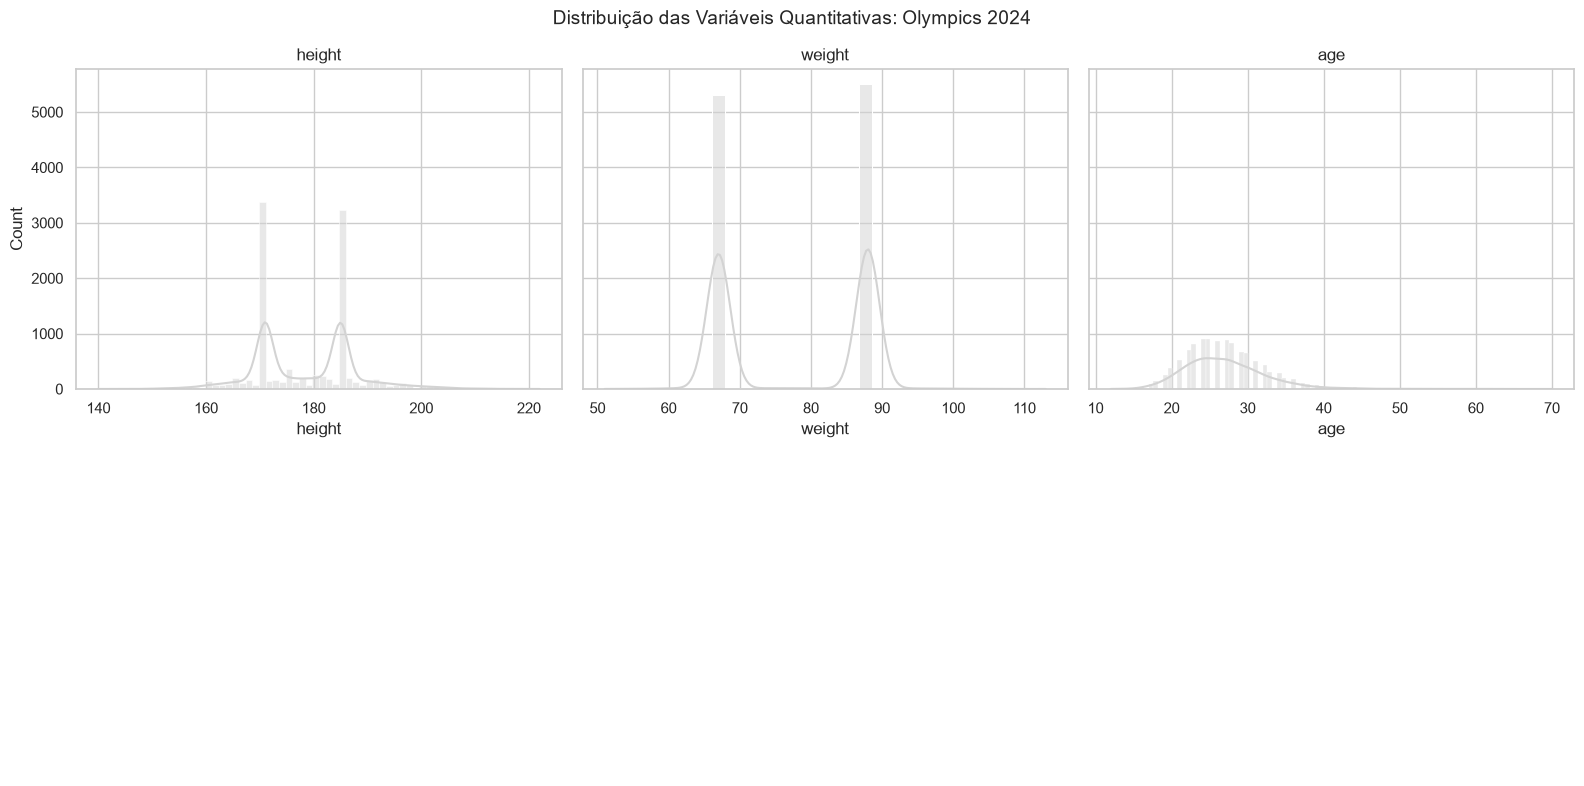

In [54]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Distribuição das Variáveis Quantitativas: Olympics 2024", fontsize=14)
plt.tight_layout()
plt.show()

In [55]:
stat_sw, p_valor_sw = stats.shapiro(df["height"].dropna())
print(f"Shapiro-Wilk — height: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

Shapiro-Wilk — height: estatística=0.9313, p-valor=2.686e-57
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


c:\Users\Samsung\Documents\AVD\.venv\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 11115.
  res = hypotest_fun_out(*samples, **kwds)


### QQ-Plot — height

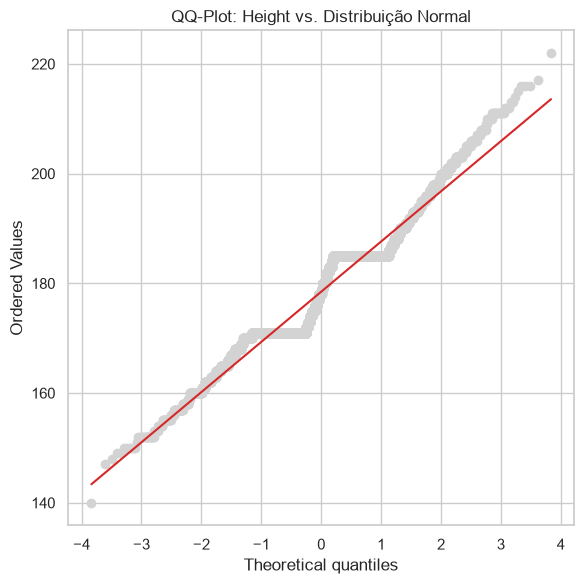

In [56]:
fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df["height"].dropna(), dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: Height vs. Distribuição Normal")
plt.tight_layout()
plt.show()

In [57]:
stat_sw, p_valor_sw = stats.shapiro(df["weight"].dropna())
print(f"Shapiro-Wilk — weight: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

Shapiro-Wilk — weight: estatística=0.6664, p-valor=1.322e-90
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


### QQ-Plot — weight

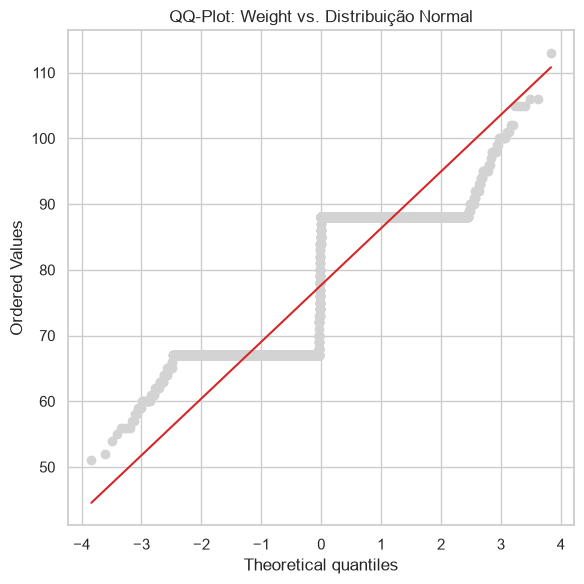

In [58]:
fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df["weight"].dropna(), dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: Weight vs. Distribuição Normal")
plt.tight_layout()
plt.show()

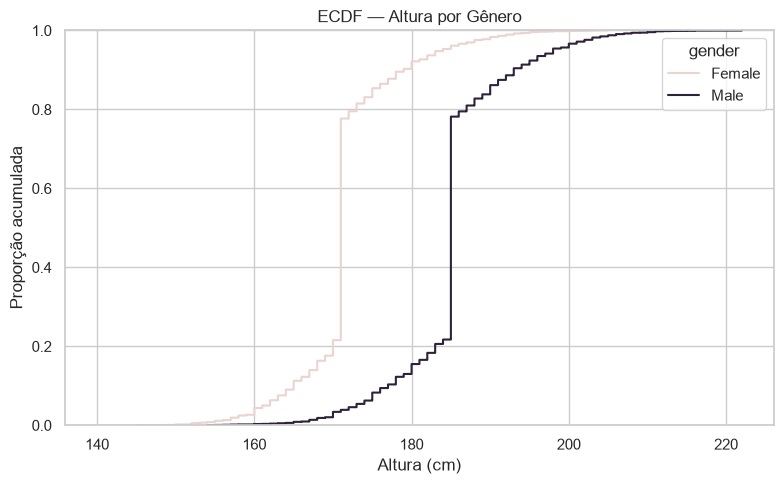

In [59]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df, x="height", hue="gender",
             palette={"Female": COR_CONTEXTO, "Male": COR_DESTAQUE})
plt.title("ECDF — Altura por Gênero")
plt.xlabel("Altura (cm)")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

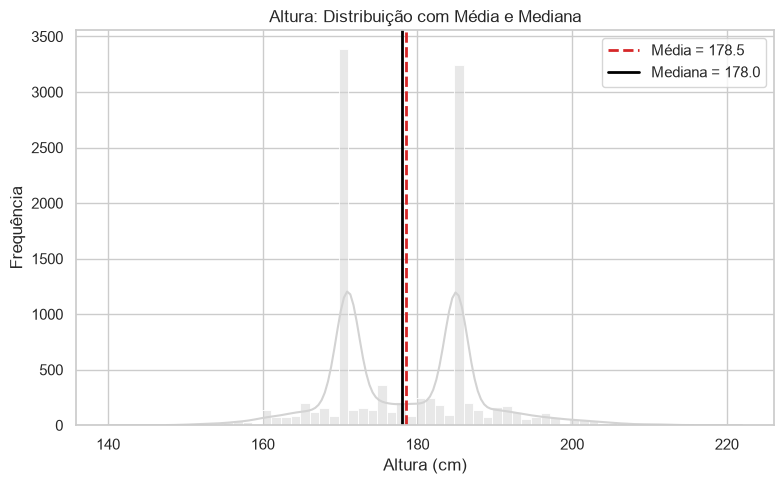

In [60]:
media_height = df["height"].mean()
mediana_height = df["height"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="height", kde=True, color=COR_NEUTRA)
plt.axvline(media_height, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_height:.1f}")
plt.axvline(mediana_height, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_height:.1f}")
plt.title("Altura: Distribuição com Média e Mediana")
plt.xlabel("Altura (cm)")
plt.ylabel("Frequência")
plt.legend()
plt.tight_layout()
plt.show()

## Resources

In [81]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
display(dispersao.round(2))

,var,std,IQR
height,89.83,9.48,14.0
weight,111.84,10.58,21.0
age,29.25,5.41,7.0


### Boxplot e violin plot por gênero

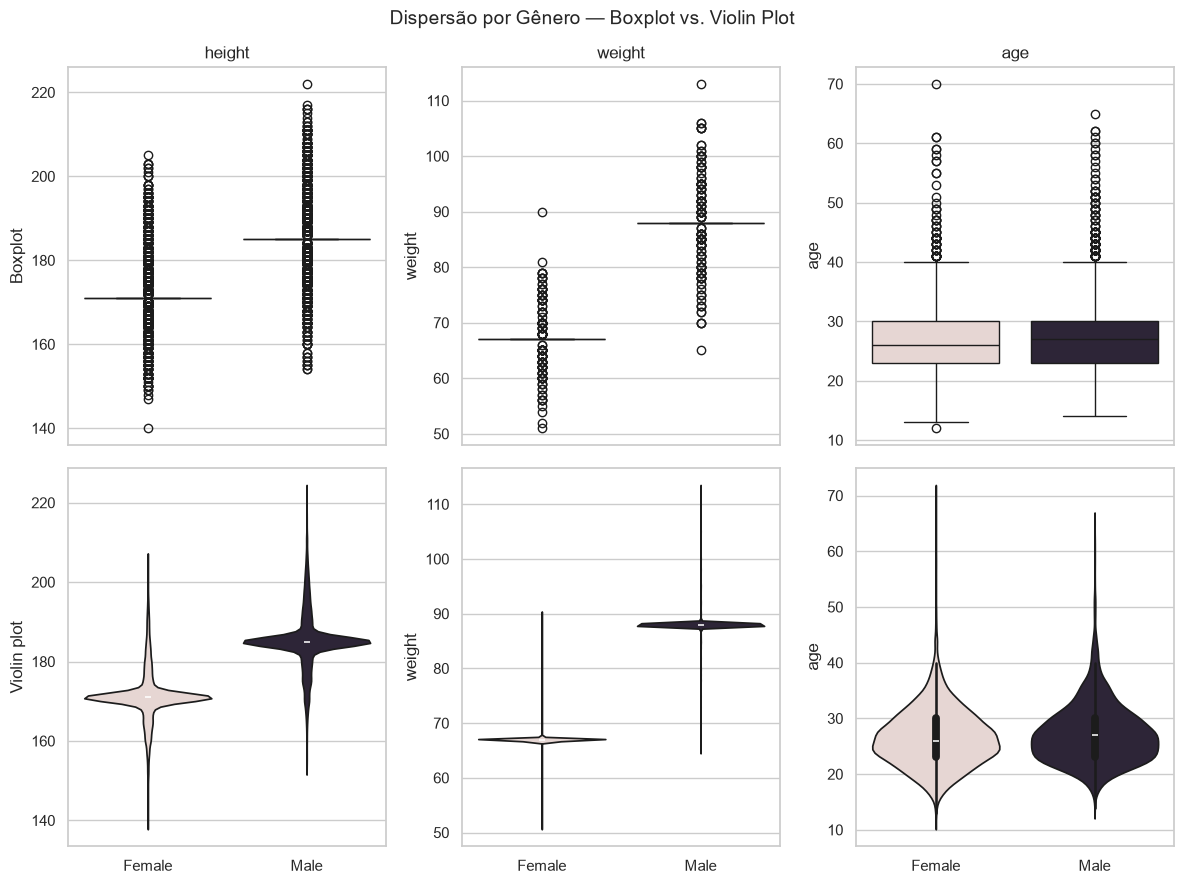

In [61]:
palette_gender = {"Female": COR_CONTEXTO, "Male": COR_DESTAQUE}

fig, axes = plt.subplots(2, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 9), sharex="col")

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, x="gender", y=col, hue="gender",
                palette=palette_gender, legend=False, ax=axes[0, i])
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    sns.violinplot(data=df, x="gender", y=col, hue="gender",
                    palette=palette_gender, legend=False, ax=axes[1, i])
    axes[1, i].set_xlabel("")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")
fig.suptitle("Dispersão por Gênero — Boxplot vs. Violin Plot", fontsize=14)
plt.tight_layout()
plt.show()

### Distribuição das Variáveis Quantitativas (Pós-Imputação)

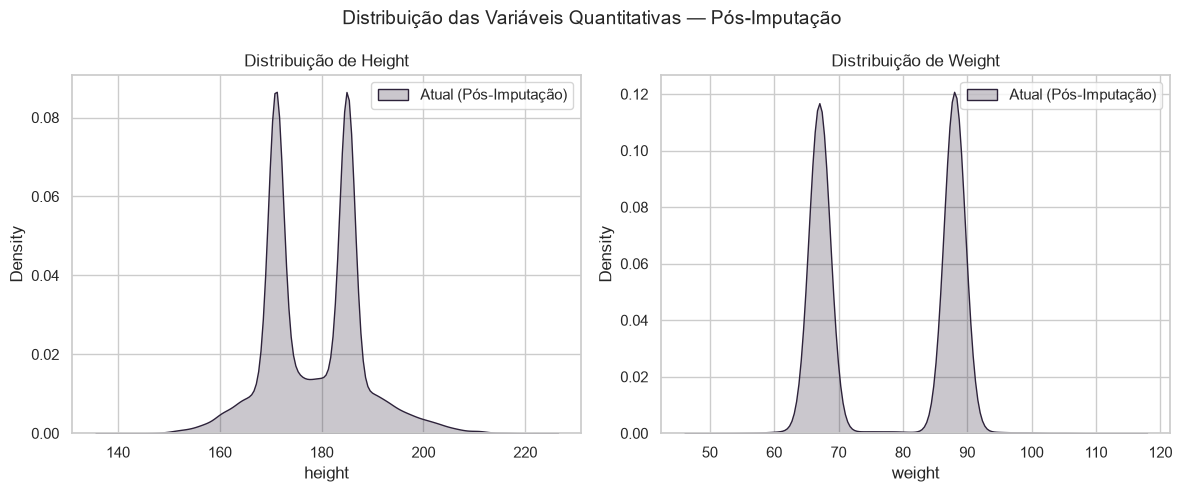

In [62]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import kagglehub
import os

# Define COR_DESTAQUE if not defined (assuming standard color setup)
try:
    COR_DESTAQUE
except NameError:
    COR_CONTEXTO = "#e9d4d0"
    COR_DESTAQUE = "#2d223a"

# Ensure df is loaded and preprocessed if not already present
if 'df' not in locals() and 'df' not in globals():
    print("Carregando e pré-processando 'df' dentro desta célula...")
    path = kagglehub.dataset_download("willianoliveiragibin/olympics-2024")
    df = pd.read_csv(os.path.join(path, 'athletes new.csv'))
    df['height'] = df['height'].replace(0, np.nan)
    df['weight'] = df['weight'].replace(0.0, np.nan)
    df['height'] = df.groupby('gender')['height'].transform(lambda x: x.fillna(x.median()))
    df['weight'] = df.groupby('gender')['weight'].transform(lambda x: x.fillna(x.median()))
    print("DataFrame 'df' carregado e pré-processado.")

# Now proceed with the rest of the code
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
VARS_QUANT = [col for col in numerical_cols if col != 'code']

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col in zip(axes, VARS_QUANT):
    sns.kdeplot(df[col], color=COR_DESTAQUE, fill=True, label="Atual (Pós-Imputação)", ax=ax)
    ax.set_title(f"Distribuição de {col.capitalize()}")
    ax.legend()

fig.suptitle("Distribuição das Variáveis Quantitativas — Pós-Imputação", fontsize=14)
plt.tight_layout()
plt.show()

### Tabelas de Frequência para Variáveis Qualitativas

In [63]:
VARS_QUALI = ['gender'] # 'gender' é a variável qualitativa mais relevante para frequência

for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\n--- {col} ---")
    display(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))


--- gender ---


,absoluta,relativa
gender,,
Male,5655,0.509
Female,5460,0.491


In [64]:
qualitative_cols = [
    col for col in df.select_dtypes(include='object').columns
    if col not in ['name', 'name_short', 'name_tv', 'nationality', 'nationality_full', 'birth_date', 'events', 'disciplines']
]
VARS_QUALI = qualitative_cols

print(f"Variáveis qualitativas para plotagem: {VARS_QUALI}")


Variáveis qualitativas para plotagem: ['gender', 'function', 'country_code', 'country', 'country_full', 'nationality_code']


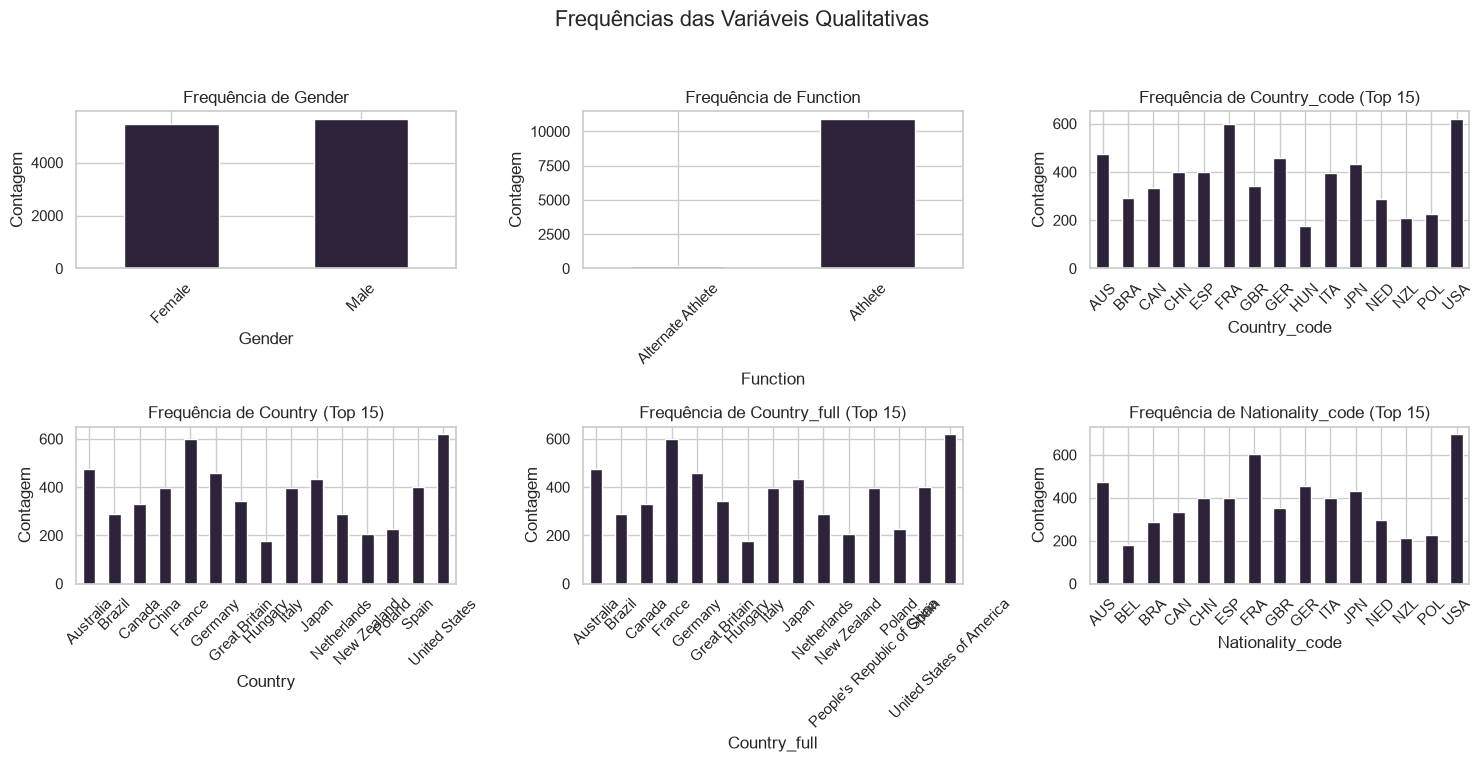

In [65]:
num_cols = len(VARS_QUALI)
num_rows = (num_cols + 2) // 3 # Adjust rows dynamically, max 3 columns per row

fig, axes = plt.subplots(num_rows, min(num_cols, 3), figsize=(5 * min(num_cols, 3), 4 * num_rows), sharey=False)

if num_rows > 1 or num_cols > 1:
    axes = axes.ravel() # Flatten the array of axes for easy iteration
else:
    axes = [axes]

for i, col in enumerate(VARS_QUALI):
    # Limit the number of categories to display to avoid clutter
    if df[col].nunique() > 20: # Example threshold, adjust as needed
        top_n = df[col].value_counts().nlargest(15).index # Take top 15 categories
        df[df[col].isin(top_n)][col].value_counts().sort_index().plot(kind="bar", color=COR_DESTAQUE, ax=axes[i])
        axes[i].set_title(f"Frequência de {col.capitalize()} (Top 15)")
    else:
        df[col].value_counts().sort_index().plot(kind="bar", color=COR_DESTAQUE, ax=axes[i])
        axes[i].set_title(f"Frequência de {col.capitalize()}")

    axes[i].set_xlabel(col.capitalize())
    axes[i].set_ylabel("Contagem")
    axes[i].tick_params(axis="x", rotation=45) # Rotate for better readability

# Turn off any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to prevent title overlap
plt.show()

In [66]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })


In [67]:
vars_para_checar = VARS_QUALI.copy()
# Remover 'doenca_cardiaca' se não existir no df
if 'doenca_cardiaca' in vars_para_checar and 'doenca_cardiaca' not in df.columns:
    vars_para_checar.remove('doenca_cardiaca')

display(pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}).T)

,n_classes,razao_desbalanceamento,entropia_normalizada
gender,2.0,1.04,1.000
function,2.0,56.00,0.127
country_code,206.0,620.00,0.804
country,206.0,620.00,0.804
country_full,206.0,620.00,0.804
nationality_code,198.0,697.00,0.803


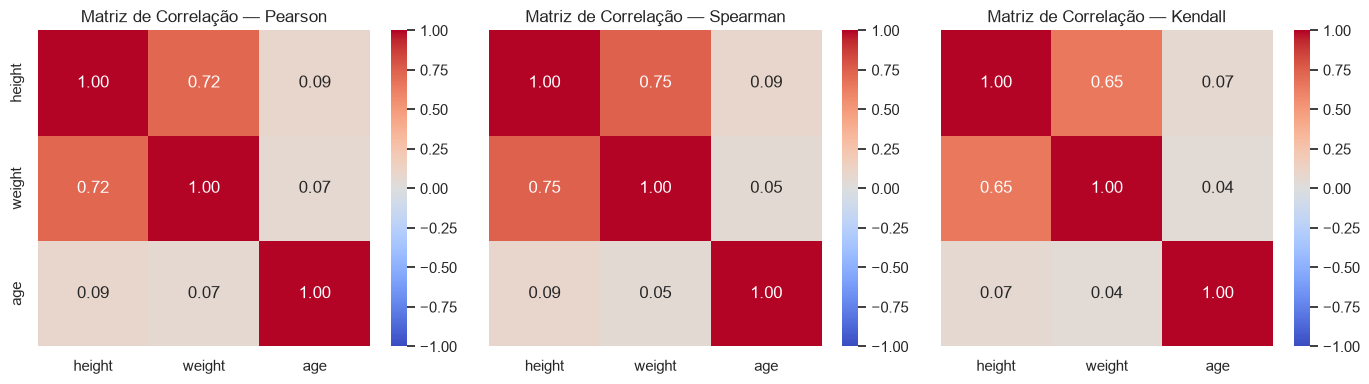

In [68]:
corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_kendall = df[VARS_QUANT].corr(method="kendall")

fig, ax = plt.subplots(1,3,figsize=(14, 4),sharey=True)
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Matriz de Correlação — Pearson")
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title("Matriz de Correlação — Spearman")
sns.heatmap(corr_kendall, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[2])
ax[2].set_title("Matriz de Correlação — Kendall")
plt.tight_layout()
plt.show()

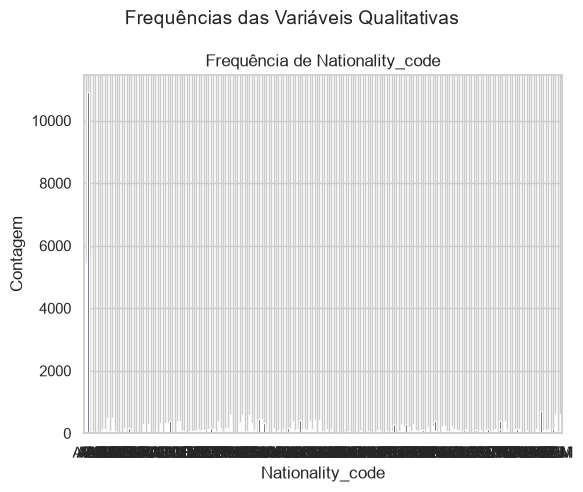

In [69]:
fig, ax = plt.subplots(1, 1, figsize=(6, 5))

for i, col in enumerate(VARS_QUALI):
    df[col].value_counts().sort_index().plot(kind="bar", color=COR_DESTAQUE, ax=ax)
    ax.set_title(f"Frequência de {col.capitalize()}")
    ax.set_xlabel(col.capitalize())
    ax.set_ylabel("Contagem")
    ax.tick_params(axis="x", rotation=0)

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=14)
plt.tight_layout()
plt.show()

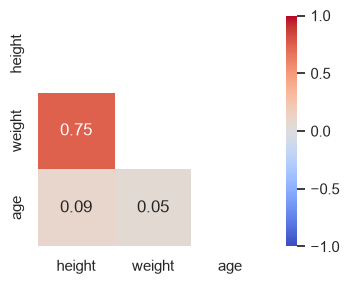

In [70]:
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(4, 3))
sns.heatmap(corr_spearman, mask=mask, annot=True, cmap="coolwarm", fmt=".2f", square=True, vmin=-1, vmax=1,)
plt.grid(False)

plt.tight_layout()
plt.show()

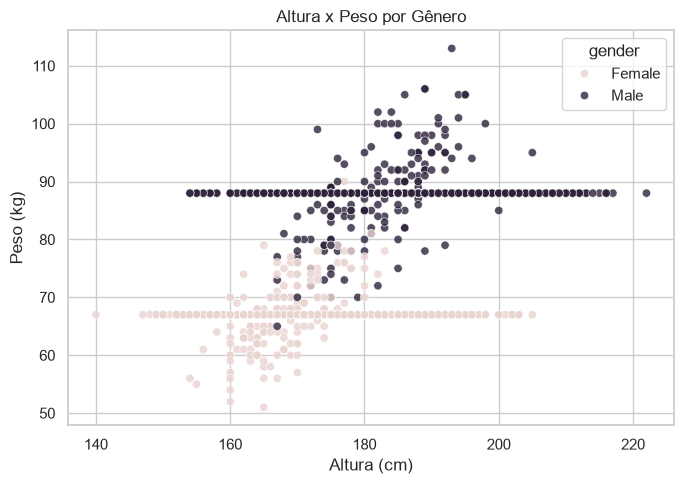

In [71]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="height", y="weight", hue="gender",
                palette={"Female": COR_CONTEXTO, "Male": COR_DESTAQUE}, alpha=0.8)
plt.title("Altura x Peso por Gênero")
plt.xlabel("Altura (cm)")
plt.ylabel("Peso (kg)")
plt.tight_layout()
plt.show()

In [72]:
from scipy import stats

resultados_comparacao = []
for col in VARS_QUANT:
    grupo_female = df.loc[df["gender"] == "Female", col]
    grupo_male = df.loc[df["gender"] == "Male", col]

    # Teste t de Welch (não assume variâncias iguais)
    stat_t, p_t = stats.ttest_ind(grupo_female, grupo_male, equal_var=False)

    # Teste de Mann-Whitney U (não-paramétrico)
    stat_u, p_u = stats.mannwhitneyu(grupo_female, grupo_male)

    resultados_comparacao.append({
        "variavel": col,
        "p_valor_ttest": round(p_t, 5),
        "p_valor_mannwhitney": round(p_u, 5),
        "concordam_alpha_0_05": (p_t < 0.05) == (p_u < 0.05),
    })

display(pd.DataFrame(resultados_comparacao).set_index("variavel"))

,p_valor_ttest,p_valor_mannwhitney,concordam_alpha_0_05
variavel,,,
height,0.0,0.0,True
weight,0.0,0.0,True
age,0.0,0.0,True


## Discussão sobre os Testes de Comparação de Grupos

**Pra discutir:** no nosso caso, para as variáveis `height` e `weight`, os dois testes (t-test de Welch e Mann-Whitney U) concordam que há uma diferença estatisticamente significativa entre os grupos de gênero. Isso é indicado pelos p-valores muito baixos (praticamente 0) para ambas as variáveis em ambos os testes.

Quando os testes divergem, como o Mann-Whitney U é um teste não-paramétrico, ele não assume a normalidade dos dados, uma premissa que já sabemos que `height` e `weight` não atendem (conforme mostrado na Seção 3). Portanto, o **Mann-Whitney U** seria o teste a ser priorizado para validar as diferenças observadas, pois ele respeita a premissa que de fato temos (dados não-normais), não a que gostaríamos de ter.

**Nota:** mantivemos o T-Test de Welch aqui só como contraste pedagógico, e pela sua robustez para amostras grandes, mesmo na ausência de normalidade perfeita. Contudo, reportar apenas o T-Test, sem essa ressalva e sem considerar a não-normalidade das variáveis, seria estatisticamente inconsistente.

### Exemplo com 3+ grupos — ANOVA x Kruskal-Wallis

Para variáveis qualitativas com 3 ou mais categorias, como a variável `function` em nosso dataset, que descreve diferentes funções dos atletas (ex: 'Athlete', 'Official'), a comparação de uma variável quantitativa entre esses grupos seria feita com:

*   **ANOVA (Análise de Variância):** a versão paramétrica, que assume normalidade e homogeneidade das variâncias dentro dos grupos.
*   **Kruskal-Wallis:** a versão não-paramétrica, equivalente à ANOVA para 3+ grupos, e a escolha mais apropriada quando a premissa de normalidade não é atendida pelas variáveis quantitativas dentro de cada grupo. Assim como para o Mann-Whitney U, a prioridade seria dada ao Kruskal-Wallis se os dados não forem normais.

ANOVA          — height entre categorias de function: estatística=5.058, p-valor=0.024529
Kruskal-Wallis — height entre categorias de function: estatística=5.534, p-valor=0.018647


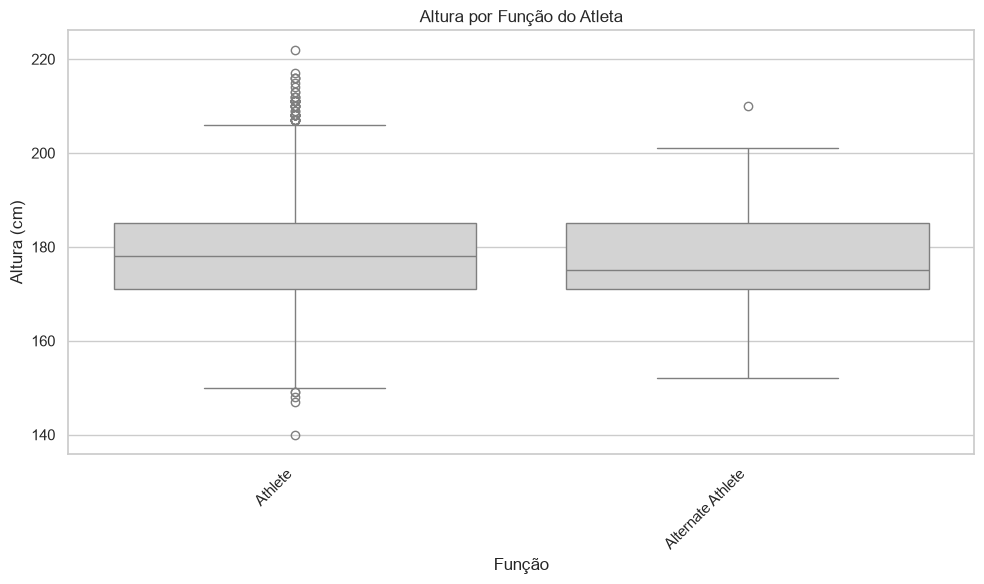

In [73]:
COR_NEUTRA = "lightgray"
COR_CONTEXTO = "#e9d4d0"
COR_DESTAQUE = "#2d223a"
COR_ALERTA = "tab:red"

grupos_function = [grupo["height"].values for _, grupo in df.groupby("function")]

stat_anova, p_anova = stats.f_oneway(*grupos_function)   # paramétrico
stat_kw, p_kw = stats.kruskal(*grupos_function)          # não-paramétrico

print(f"ANOVA          — height entre categorias de function: estatística={stat_anova:.3f}, p-valor={p_anova:.5g}")
print(f"Kruskal-Wallis — height entre categorias de function: estatística={stat_kw:.3f}, p-valor={p_kw:.5g}")

plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="function", y="height", color=COR_NEUTRA)
plt.title("Altura por Função do Atleta")
plt.xlabel("Função")
plt.ylabel("Altura (cm)")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Discussão sobre ANOVA e Kruskal-Wallis para 'height' vs 'function'

**Pra discutir:** Para a variável `height` em relação às diferentes categorias de `function`, os dois testes (ANOVA e Kruskal-Wallis) concordam que existe uma diferença estatisticamente significativa entre pelo menos uma categoria de `function`. Ambos os p-valores foram menores que 0.05 (p-valor ANOVA = 0.02453, p-valor Kruskal-Wallis = 0.01865).

Como já sabemos que `height` não segue uma distribuição normal (conforme verificado com o teste de Shapiro-Wilk e QQ-Plots anteriormente), o **Kruskal-Wallis** é o resultado que deveríamos reportar como principal. Ele é um teste não-paramétrico e, portanto, mais apropriado quando a premissa de normalidade não é atendida. A ANOVA fica aqui para fins de contraste pedagógico, ilustrando a diferença de abordagem e como, em certas situações (como amostras grandes), ambos os testes podem apontar para conclusões semelhantes, mesmo com a violação de premissas paramétricas.

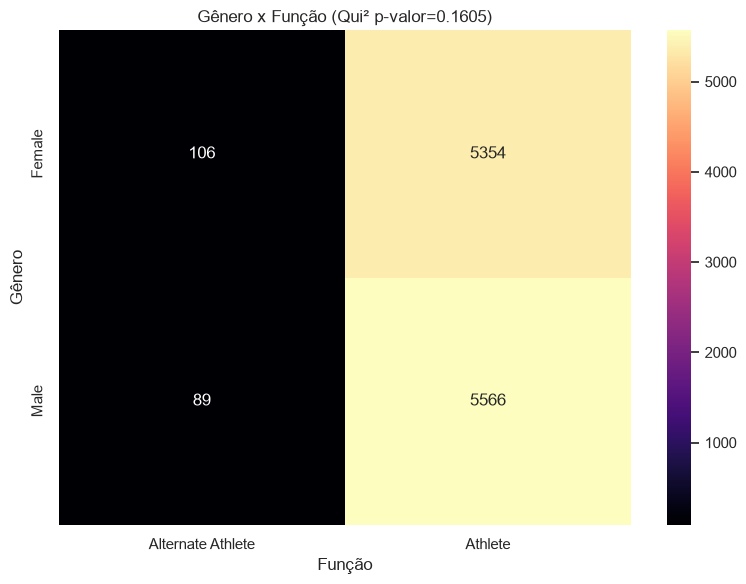

In [74]:
contingencia_genero_funcao = pd.crosstab(df["gender"], df["function"]) # Usando gender e function
chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia_genero_funcao)

fig, ax = plt.subplots(figsize=(8, 6)) # Ajustei o tamanho para melhor visualização
sns.heatmap(contingencia_genero_funcao, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title(f"Gênero x Função (Qui² p-valor={p_chi2:.4g})")
plt.xlabel("Função")
plt.ylabel("Gênero")
plt.tight_layout()
plt.show()

Desbalanceamento — gender:
n_classes                 2.00
razao_desbalanceamento    1.04
entropia_normalizada      1.00
dtype: float64

Desbalanceamento — faixa etária:
n_classes                  4.000
razao_desbalanceamento    38.780
entropia_normalizada       0.616
dtype: float64


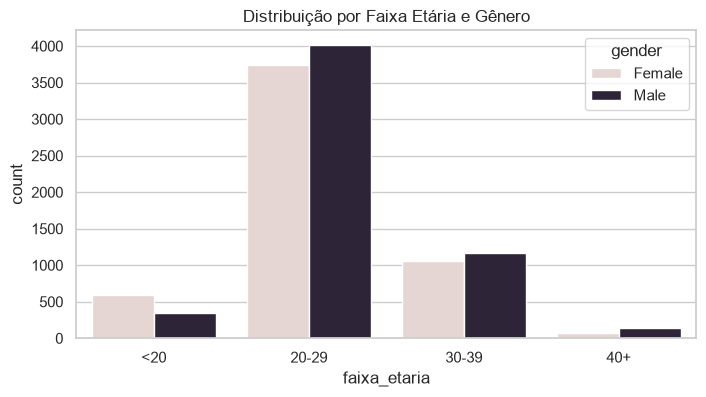

In [75]:
import datetime

# Calculando idade aproximada baseada no birth_date
ano_atual = 2024
df['birth_date'] = pd.to_datetime(df['birth_date'], errors='coerce')
df['age'] = ano_atual - df['birth_date'].dt.year

# Criando a faixa etária conforme seu exemplo
df["faixa_etaria"] = pd.cut(df["age"], bins=[0, 20, 30, 40, 100],
                             labels=["<20", "20-29", "30-39", "40+"])

print("Desbalanceamento — gender:")
print(metrica_desbalanceamento(df["gender"]))

print("\nDesbalanceamento — faixa etária:")
print(metrica_desbalanceamento(df["faixa_etaria"]))

# Plot para visualização rápida da nova variável
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='faixa_etaria', hue='gender', palette={'Female': COR_CONTEXTO, 'Male': COR_DESTAQUE})
plt.title("Distribuição por Faixa Etária e Gênero")
plt.show()

### **Pra discutir: Fairness e Padrões nos Dados**

A pergunta "a distribuição do desfecho é uniforme entre grupos?" é o ponto de partida de várias discussões de **fairness** (equidade) em ciência de dados. No nosso dataset de atletas:

1. **Gênero:** Observamos uma proporção de quase 1:1. Isso reflete um esforço deliberado do Comitê Olímpico Internacional (COI) para atingir a paridade de gênero nos Jogos modernos. Aqui, o equilíbrio é um padrão real buscado ativamente.

2. **Faixa Etária:** Vimos um desbalanceamento extremo (razão de ~38.7). Isso reflete um **padrão biológico e profissional real**: o alto rendimento esportivo atinge o pico em janelas de idade específicas (geralmente entre 20 e 30 anos). Diferente de um erro de amostragem ou viés clínico, esse desbalanceamento é inerente ao domínio do problema.

**Reflexão:** Se estivéssemos treinando um modelo para prever performance, o desbalanceamento etário poderia fazer com que o modelo fosse injusto com atletas mais velhos (40+). Não há resposta única: a disparidade pode ser um fato da natureza (risco cardíaco que cresce com a idade) ou um artefato de quem chega até o dado (quem é encaminhado para exames). No esporte, é a própria definição da elite competitiva.

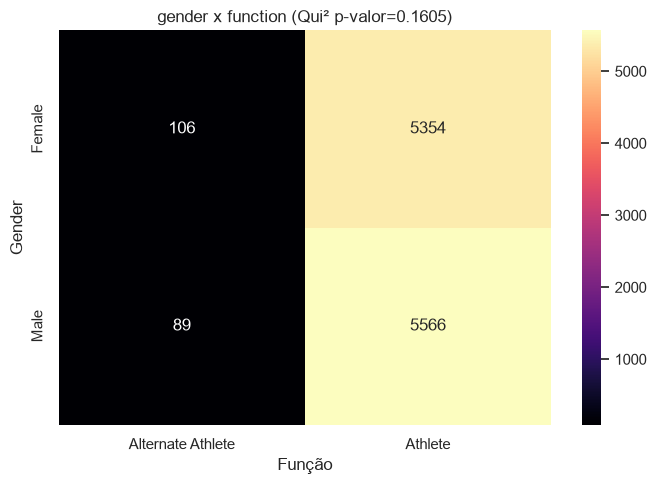

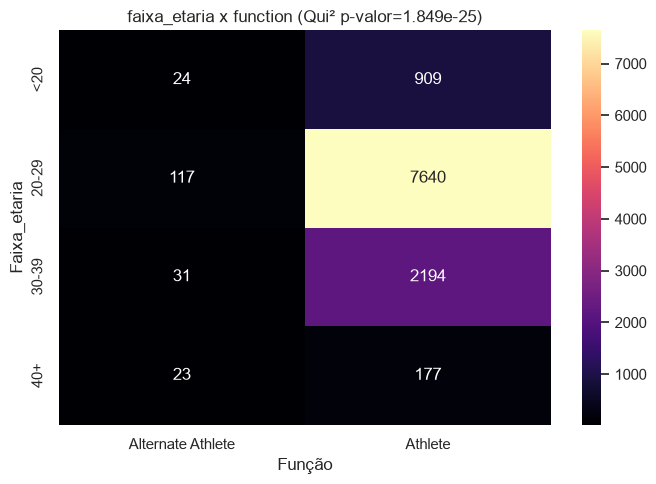

In [76]:
for atributo in ["gender", "faixa_etaria"]:
    # Criando a tabela de contingência cruzando com 'function'
    contingencia = pd.crosstab(df[atributo], df["function"])
    chi2, p_valor, gl, esperado = stats.chi2_contingency(contingencia)

    fig, ax = plt.subplots(figsize=(7, 5))
    sns.heatmap(contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
    ax.set_title(f"{atributo} x function (Qui² p-valor={p_valor:.4g})")
    plt.xlabel("Função")
    plt.ylabel(atributo.capitalize())
    plt.tight_layout()
    plt.show()

Com base nos testes de Qui-Quadrado realizados nas células anteriores, podemos tirar conclusões importantes para a nossa discussão de fairness:

Gênero vs. Função (Desfecho): O p-valor foi de 0.1605. Como é maior que 0.05, não há associação estatisticamente significativa. Isso sugere que a distribuição de atletas titulares e reservas é equilibrada entre gêneros, não indicando viés aparente nessa amostra.

Faixa Etária vs. Função (Desfecho): O p-valor foi extremamente baixo (1.849e-25), confirmando uma associação estatisticamente significativa.

Discussão de Fairness: O teste confirma que a idade e a função na equipe estão ligadas, mas reforça o que você mencionou: correlação não é causalidade.

Fator de Risco/Performance (Real): Atletas entre 20-29 anos estão no auge biológico para a maioria dos esportes, o que explica a alta concentração de titulares nessa faixa.
Viés de Encaminhamento/Seleção: O número elevado de reservas em certas faixas pode ser uma estratégia das federações (levar jovens para ganhar experiência ou veteranos para liderança), e não apenas uma métrica de performance pura.
Em resumo: o Qui-Quadrado detectou o padrão (a disparidade etária é real e não aleatória), mas cabe a nós, como analistas, discernir se isso é uma injustiça algorítmica ou uma característica intrínseca do domínio esportivo.

### Análise de Outliers Conjuntos (Altura vs. Peso)

Utilizaremos um `jointplot` para visualizar a relação entre altura e peso simultaneamente às suas distribuições marginais, identificando possíveis outliers que combinam características extremas de ambas as variáveis.

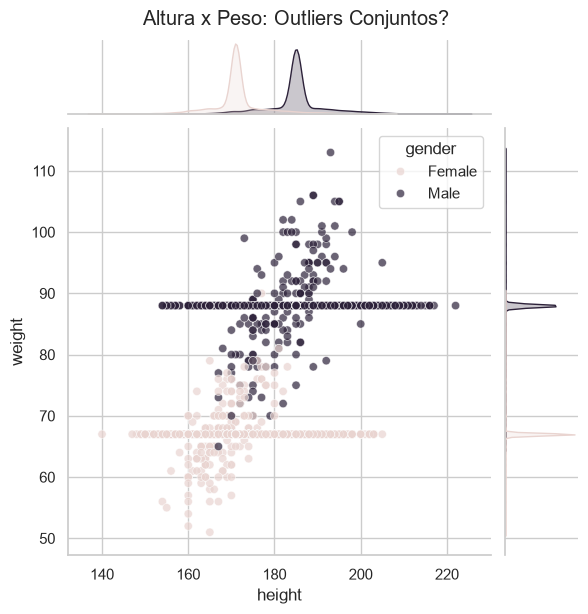

In [77]:
import matplotlib.pyplot as plt
import seaborn as sns

# Adaptando o código solicitado para o dataset de atletas
# x="trestbps" -> "height"
# y="chol"     -> "weight"
# hue="doenca_cardiaca" -> "gender"

g = sns.jointplot(data=df, x="height", y="weight", hue="gender",
              palette={"Female": COR_CONTEXTO, "Male": COR_DESTAQUE},
              alpha=0.7, height=6)

plt.suptitle("Altura x Peso: Outliers Conjuntos?", y=1.02)
plt.show()

In [78]:
# 🆕 NOVA CÉLULA — define as pastas de destino (funciona rodando de notebooks/ ou da raiz do projeto)
from pathlib import Path

RAIZ = Path("..") if Path("../data").exists() else Path(".")
PASTA_RAW = RAIZ / "data" / "raw"
PASTA_CLEAN = RAIZ / "data" / "clean"
PASTA_RAW.mkdir(parents=True, exist_ok=True)
PASTA_CLEAN.mkdir(parents=True, exist_ok=True)

In [79]:
# 🆕 NOVA CÉLULA — dataset ORIGINAL (recarregado diretamente da fonte)
df_raw = pd.read_csv(os.path.join(path, 'athletes new.csv'))
df_raw.to_csv(PASTA_RAW / "dataset.csv", index=False)

print(f"Raw salvo em {PASTA_RAW / 'dataset.csv'} — {df_raw.shape[0]} linhas x {df_raw.shape[1]} colunas")

Raw salvo em ..\data\raw\dataset.csv — 11115 linhas x 17 colunas


In [80]:
# 🆕 NOVA CÉLULA — dataset TRATADO (estado final do `df`)
df.to_csv(PASTA_CLEAN / "dataset.csv", index=False)

print(f"Clean salvo em {PASTA_CLEAN / 'dataset.csv'} — {df.shape[0]} linhas x {df.shape[1]} colunas")
print(f"Linhas removidas no tratamento: {df_raw.shape[0] - df.shape[0]}")

Clean salvo em ..\data\clean\dataset.csv — 11115 linhas x 19 colunas
Linhas removidas no tratamento: 0
